In [1]:
# %pip install numpy pandas matplotlib seaborn scikit-learn opencv-python-headless
# %pip install kagglehub
# %pip install pydot
# !apt-get update -qq && apt-get install -y graphviz

In [2]:
print('hello')

hello


In [3]:
import numpy as np
import pandas as pd
import os
import kagglehub
import pathlib
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, Dense, Dropout
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from pathlib import Path
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, BackupAndRestore
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from tensorflow.keras.models import load_model
import time
from tensorflow.image import resize

I0000 00:00:1792858556.195420    6051 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [4]:
# gpus = tf.config.list_physical_devices('GPU')
# if gpus:
#       try:
#             # Currently, memory growth needs to be the same across GPUs
#             for gpu in gpus:
#                   tf.config.experimental.set_memory_growth(gpu, True)
#                   logical_gpus = tf.config.list_logical_devices('GPU')
#                   print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
#       except RuntimeError as e:
#       # Memory growth must be set before GPUs have been initialized
#             print(e)

In [4]:
RAMDOM_STATE = 42
BATCH_SIZE= 32
EPOCHS = 20
image_size = (224, 224)

In [5]:
extensions_valides = (".jpg", ".jpeg", ".png", ".bmp")

labels_par_dossier = {
    "glioma": 0,
    "meningioma": 1,
    "notumor" : 2,
    "pituitary" : 3
}

In [6]:
# Download latest version

dataset_path = Path(
      "/root/.cache/kagglehub/datasets/devana2004/dataset/versions/1/Data"
)

if dataset_path.exists() and any(dataset_path.iterdir()):
      print("✅ Dataset déjà présent dans le cache.")
      print("Chemin :", dataset_path)
      print("Contenu :", [p.name for p in dataset_path.iterdir()])
else:
      print("❌ Dataset absent ou dossier vide.")
      dataset_path = kagglehub.dataset_download("devana2004/dataset")
      dataset_path = dataset_path +'/Data'


print("Path to dataset files:", dataset_path)

Path("transfer_learning").mkdir(parents=True, exist_ok=True)


✅ Dataset déjà présent dans le cache.
Chemin : /root/.cache/kagglehub/datasets/devana2004/dataset/versions/1/Data
Contenu : ['glioma', 'meningioma', 'notumor', 'pituitary']
Path to dataset files: /root/.cache/kagglehub/datasets/devana2004/dataset/versions/1/Data


Pretraitement pour ameliorer la qualite de l'image affin de pourvoir analyser des qualites specifiques et essentiels

In [7]:
def check_data(path, extensions_valides, labels_par_dossier):
    images = []
    labels = []

    num_skipped = 0
    num_corrompu = 0

    data_dir = Path(path)
    extensions_valides = {
        ext.lower() if ext.startswith(".") else f".{ext.lower()}"
        for ext in extensions_valides
    }

    for folder in data_dir.iterdir():
        if not folder.is_dir():
            continue

        # Ignorer les dossiers qui ne correspondent pas aux classes
        if folder.name not in labels_par_dossier:
            continue

        for file in folder.iterdir():
            if not file.is_file():
                continue

            # Vérifier l'extension avant de décoder l'image
            if file.suffix.lower() not in extensions_valides:
                num_skipped += 1
                continue

            image = cv2.imread(str(file))

            if image is None:
                num_corrompu += 1
                continue

            # BGR -> RGB
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            # Redimensionnement pour MobileNetV2
            image = cv2.resize(image, (224, 224))

            images.append(image)
            labels.append(labels_par_dossier[folder.name])

    print(f"Fichiers ignorés : {num_skipped}")
    print(f"Images corrompues : {num_corrompu}")
    print(f"Images chargées : {len(images)}")
    print(f"Labels chargés : {len(labels)}")

    return images, labels
images, labels = check_data(dataset_path, extensions_valides,  labels_par_dossier)

Fichiers ignorés : 0
Images corrompues : 0
Images chargées : 7023
Labels chargés : 7023


In [8]:
def preparing_data(images, labels,image_size=(224, 224)):

    images_resized =[]
    
    for image in images:
        resized = cv2.resize(image, image_size, interpolation=cv2.INTER_LINEAR)
        images_resized.append(resized)
    
    X = np.asarray(images_resized, dtype=np.uint8)
    
    y = np.asarray(labels, dtype=np.int32)

    if len(X) != len(y):
        raise ValueError(
            "Le nombre d'images doit correspondre au nombre de labels."
        )
    
    return X, y

images_array_2d, labeles_array_2d = preparing_data(images=images, labels=labels,image_size=image_size)
print(images_array_2d.shape, labeles_array_2d.shape)

(7023, 224, 224, 3) (7023,)


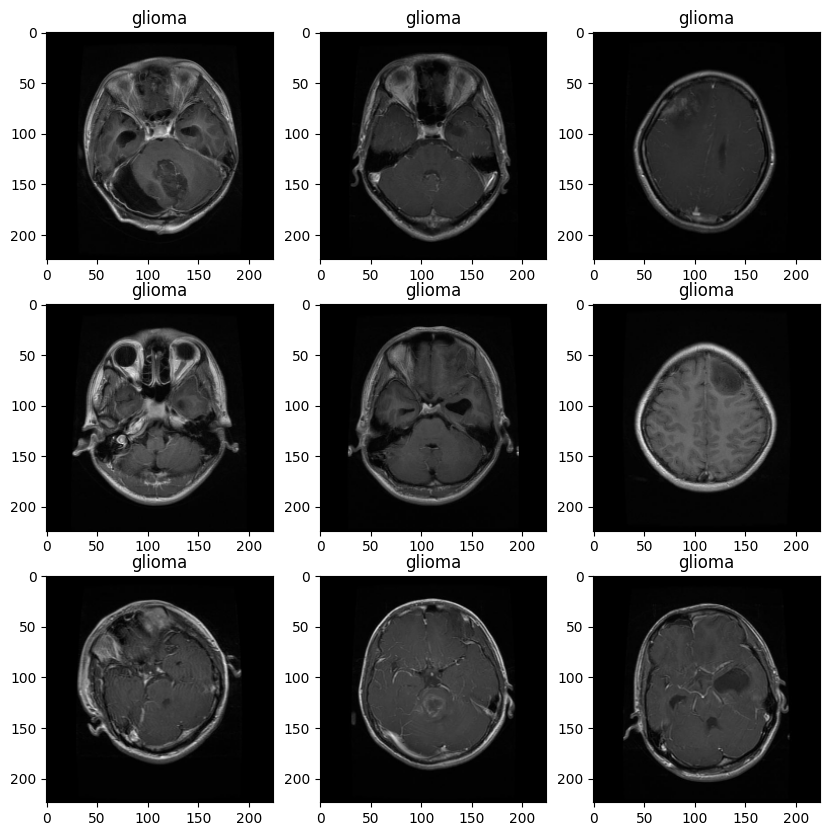

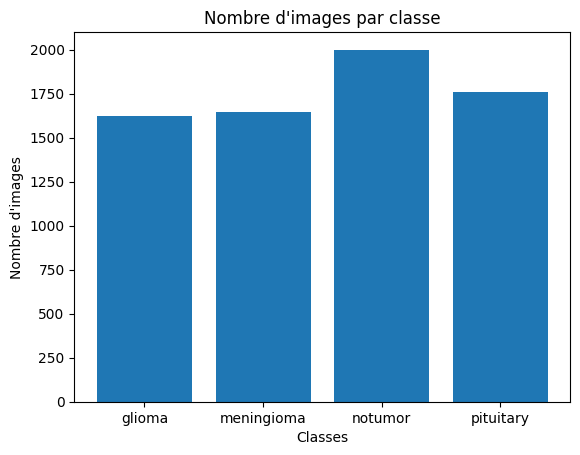

<Figure size 640x480 with 0 Axes>

In [10]:
plt.figure(figsize=(10,10))
n_images = min(9, len(images))

for i in range(n_images):
    ax = plt.subplot(3,3,i+1)
    image_rgb = cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB)
    plt.imshow(image_rgb)
    nom_class = next((k for k, v in labels_par_dossier.items() if v == labels[i]), None)
    plt.title(nom_class)
plt.show()
plt.savefig('transfer_learning/example1.png')

effectifs = Counter(labels)

noms_classes = list(labels_par_dossier.keys())
nombres_images = [
    effectifs[labels_par_dossier[nom]]
    for nom in noms_classes
]

# for nom, nombre in zip(noms_classes, nombres_images):
#     print(f'{nom} : {nombre} images')

plt.bar(noms_classes, nombres_images)
plt.title("Nombre d'images par classe")
plt.xlabel('Classes')
plt.ylabel("Nombre d'images")
plt.show()
plt.savefig('transfer_learning/image_par_class.png')

In [9]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
def spliting_data(X, y, random_state=42):

    X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.20, stratify=y, random_state=random_state)

    X_test, X_val, y_test, y_val = train_test_split(X_tmp, y_tmp, test_size=0.5,  stratify=y_tmp, random_state=random_state)

    print(X_train.shape, X_test.shape, X_val.shape)

    print(y_train.shape, y_test.shape, y_val.shape)

    return  X_train, X_test, X_val, y_train, y_test, y_val

X_train, X_test, X_val, y_train, y_test, y_val = spliting_data(images_array_2d, labeles_array_2d, random_state=RAMDOM_STATE)


# def  normalisation(X, seuil):
#     return X.astype('float32') / seuil


def preprocess(image,label):
    # image = resize(image,image_size)
    image = tf.cast(image, tf.float32)

    # Prétraitement officiel de MobileNetV2 : pixels vers [-1, 1]
    image = preprocess_input(image)
    label = tf.cast(label, tf.int32)

    return image, label

def prep(X, y, training=True):

    # X = normalisation(X, 255.0)
    X_ds = tf.data.Dataset.from_tensor_slices((X, y))


    if training:
        X_ds = X_ds.shuffle(buffer_size=len(X), seed=RAMDOM_STATE, reshuffle_each_iteration=True)
        
    X_ds = X_ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    
    X_ds = X_ds.batch(batch_size=BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)

    return X_ds


Train_ds =  prep(X_train, y_train, training=True)
Test_ds = prep(X_test, y_test, training=False)
Val_ds = prep(X_val, y_val, training=False)
print(Train_ds, Test_ds, Val_ds)

(5618, 224, 224, 3) (702, 224, 224, 3) (703, 224, 224, 3)
(5618,) (702,) (703,)


I0000 00:00:1792858625.536220    6051 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 11530 MB memory:  -> device: 0, name: NVIDIA TITAN Xp, pci bus id: 0000:06:00.0, compute capability: 6.1
I0000 00:00:1792858625.536877    6051 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 11530 MB memory:  -> device: 1, name: NVIDIA TITAN Xp, pci bus id: 0000:0b:00.0, compute capability: 6.1
W0000 00:00:1792858625.540154    6051 cpu_allocator_impl.cc:82] Allocation of 845666304 exceeds 10% of free system memory.
W0000 00:00:1792858626.258514    6051 cpu_allocator_impl.cc:82] Allocation of 845666304 exceeds 10% of free system memory.


<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))> <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))> <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


In [27]:
import tensorflow as tf
from tensorflow.keras import layers, models
from pathlib import Path
import time


def build_data_augmentation():
      return tf.keras.Sequential([
            layers.RandomRotation(0.05),
            layers.RandomZoom(
                  height_factor=(-0.2, 0.2),
                  width_factor=(-0.2, 0.2)
            ),
            layers.RandomTranslation(
                  height_factor=0.05,
                  width_factor=0.05
            ),
            layers.RandomZoom(0.1)
            ], name="data_augmentation")

def build_model(image_size=(224, 224),dropout_rate=0.2, num_classes=4):

      data_augmentation= build_data_augmentation()

      base_model = tf.keras.applications.MobileNetV2(
            input_shape=image_size + (3,), include_top=False,
            weights='imagenet'
      )

      #Transfert_Learning : geler le backbone
      base_model.trainable = False

      inputs = tf.keras.Input(shape=(image_size +(3,)))
      x = data_augmentation(inputs)

      # Les images sont déjà prétraitées dans Train_ds
      x = base_model(x, training=False)

      x = layers.GlobalAveragePooling2D()(x)

      x= tf.keras.layers.Dropout(0.2)(x)

      #Sortie en probabilites pour les 4 classes
      outputs = layers.Dense(num_classes, activation='softmax')(x)

      model = tf.keras.Model(inputs, outputs)

      return model, base_model

def compile_mode(model, learning_rate=1e-5):
      model.compile(
            optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate),
            loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
            metrics=['accuracy']
      )

      return model

def evaluate_initial_model(model, val_ds):
      loss, accuracy = model.evaluate(val_ds, verbose=1)

      print(f"Loss initiale : {loss:.4f}")
      print(f"Accuracu initiale : {accuracy:.4f}")

      return {
            "initial_val_loss": float(loss),
            "initial_val_accuracy": float(accuracy)
      }

def create_callbacks(output_dir, backup_dir):
      output_dir = Path(output_dir)
      backup_dir = Path(backup_dir)

      output_dir.mkdir(parents=True, exist_ok=True)
      backup_dir.mkdir(parents=True, exist_ok=True)

      checkpoint_best = tf.keras.callbacks.ModelCheckpoint(
            filepath=str(output_dir / 'best_model.keras'),
            monitor='val_loss',
            mode='min',
            save_best_only=True,
            verbose=1
      )

      early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=4,
            restore_best_weights=True,
            verbose=1
      )

      backup = tf.keras.callbacks.BackupAndRestore(
            backup_dir=str(backup_dir),
            save_freq='epoch',
            double_checkpoint=True,
            delete_checkpoint=False
      )

      return [checkpoint_best, early_stopping, backup]

def train_model(model, train_ds, val_ds, epochs, callbacks):

      debut = time.time()

      history = model.fit(
            train_ds,
            epochs=epochs,
            validation_data=val_ds,
            callbacks=callbacks
      )

      duree = time.time() - debut

      print(f"Durée : {duree:.2f} secondes")
      print(f"Durée : {duree /60:.2f} minutes")

      return (history, duree)


def degler_layers(base_model, num_layers=30):

      #Degeler le model pouir permettre le fine-tuning
      base_model.trainable = True

      cutoff = max(0, len(base_model.layers) - num_layers)

      for i, layer in enumerate(base_model.layers):
            layer.trainable = (
                  i >= cutoff
                  and not isinstance(layer, tf.keras.layers.BatchNormalization)
            )

      return base_model

In [ ]:

OUTPUT_DIR = "/transfer_learning/models"
BACKUP_DIR = "/transfer_learning/backup"

# 1. Construire le modèle
model, base_model = build_model(
      image_size=(224, 224),
      num_classes=4,
      dropout_rate=0.2
)

# 2. Compiler
model = compile_mode(model, learning_rate=0.0001)

# 3. Vérifier l'architecture
model.summary()

# 4. Évaluer avant entraînement
initial_metrics = evaluate_initial_model(model, Val_ds)

# 5. Créer les callbacks
callbacks = create_callbacks(OUTPUT_DIR, BACKUP_DIR)

# 6. Entraîner
history, training_duration = train_model(
      model,
      Train_ds,
      Val_ds,
      epochs=EPOCHS,
      callbacks=callbacks
)




Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

I0000 00:00:1792858681.443895    6578 cuda_dnn.cc:461] Loaded cuDNN version 90300


22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - accuracy: 0.1821 - loss: 1.8840
Loss initiale : 1.8840
Accuracu initiale : 0.1821
Durée : 0.62 secondes
Durée : 0.01 minutes


In [ ]:
def  build_cnn(data_augmentation):

      """Construit le CNN de base comme dans le notebook."""
      
      # API Sequentiel
      model = models.Sequential()
      model.add(layers.Input(shape=(224, 224, 3)))
      model.add(data_augmentation)
      model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)))
      model.add(layers.MaxPooling2D((2, 2)))
      model.add(layers.Conv2D(64, (3, 3), activation='relu'))
      model.add(layers.MaxPooling2D((2, 2)))
      model.add(layers.Conv2D(64, (3, 3), activation='relu'))
      model.add(layers.Flatten())
      model.add(layers.Dense(64, activation='relu'))
      model.add(layers.Dense(4))

      return model

OUTPUT_DIR = "/cnn/models"
BACKUP_DIR = "/cnn/backup"

# 1. Construire le modèle
model = build_cnn()

# 2. Compiler
model = compile_mode(model, learning_rate=0.0001)

# 3. Vérifier l'architecture
model.summary()

# 4. Évaluer avant entraînement
initial_metrics = evaluate_initial_model(model, Val_ds)

# 5. Créer les callbacks
callbacks = create_callbacks(OUTPUT_DIR, BACKUP_DIR)

# 6. Entraîner
history, training_duration = train_model(
      model,
      Train_ds,
      Val_ds,
      epochs=EPOCHS,
      callbacks=callbacks
)




In [28]:
OUTPUT_DIR = "/fine_tuning/models"
BACKUP_DIR = "/fine_tuning/backup"
base_model  = degler_layers(base_model=base_model, num_layers=30)

model = compile_mode(model, learning_rate=1e-5)
model.summary()
print(
    "Couches entraînables dans MobileNetV2 :",
    sum(layer.trainable for layer in base_model.layers),
    "/",
    len(base_model.layers)
)
initial_metrics = evaluate_initial_model(model, Val_ds)

# 5. Créer les callbacks
callbacks = create_callbacks(OUTPUT_DIR, BACKUP_DIR)

# 6. Entraîner
history, training_duration = train_model(
      model,
      Train_ds,
      Val_ds,
      epochs=EPOCHS,
      callbacks=callbacks
)

Model: "functional_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_21 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Couches entraînables dans MobileNetV2 : 19 / 154
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.8108 - loss: 0.5073
Loss initiale : 0.5073
Accuracu initiale : 0.8108
Epoch 1/20


W0000 00:00:1792863798.646065    6051 cpu_allocator_impl.cc:82] Allocation of 845666304 exceeds 10% of free system memory.


176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.8690 - loss: 0.3580
Epoch 1: val_loss improved from None to 0.52718, saving model to /fine_tuning/models/best_model.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 16s 61ms/step - accuracy: 0.8733 - loss: 0.3470 - val_accuracy: 0.8065 - val_loss: 0.5272
Epoch 2/20
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.8707 - loss: 0.3501
Epoch 2: val_loss did not improve from 0.52718
176/176 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.8715 - loss: 0.3503 - val_accuracy: 0.8051 - val_loss: 0.5307
Epoch 3/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.8829 - loss: 0.3385
Epoch 3: val_loss did not improve from 0.52718
176/176 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.8734 - loss: 0.3392 - val_accuracy: 0.8065 - val_loss: 0.5306
Epoch 4/20
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.8678 - loss: 0.3564
Epoch 4: val_loss did not improve from 0.52718
176/176 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.8677 -

In [29]:
model = tf.keras.models.load_model(
    "/transfer_learning/models/best_model.keras"
)

In [33]:
for layer in model.layers:
      # print(layer.name, type(layer).__name__)
      if layer.name == 'mobilenetv2_1.00_224':
            print(
            "Couches entraînables dans MobileNetV2 :",
            sum(layer.trainable for layer in layer.layers),
            "/",
            len(layer.layers)
)

Couches entraînables dans MobileNetV2 : 1 / 154


In [ ]:
# if layer == "mobilenetv2_1.00_224" for 

In [14]:
for image_batch, label_batch in Train_ds:
    print(image_batch.shape)
    print(label_batch.shape)
    break

(32, 224, 224, 3)
(32,)


In [15]:
for images, labels in Train_ds.take(1):
      print("Forme des images :", images.shape)
      print("Valeur minimale :", float(tf.reduce_min(images)))
      print("Valeur maximale :", float(tf.reduce_max(images)))
      print("Labels :", labels[:10].numpy())

Forme des images : (32, 224, 224, 3)
Valeur minimale : -1.0
Valeur maximale : 1.0
Labels : [1 2 3 1 3 0 3 3 0 1]


2026-10-24 14:02:30.212890: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [16]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(
        height_factor=(-0.2, 0.2),
        width_factor=(-0.2, 0.2)
    ),
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),
    layers.RandomZoom(0.1)
], name="data_augmentation")

2026-10-24 14:02:51.988983: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


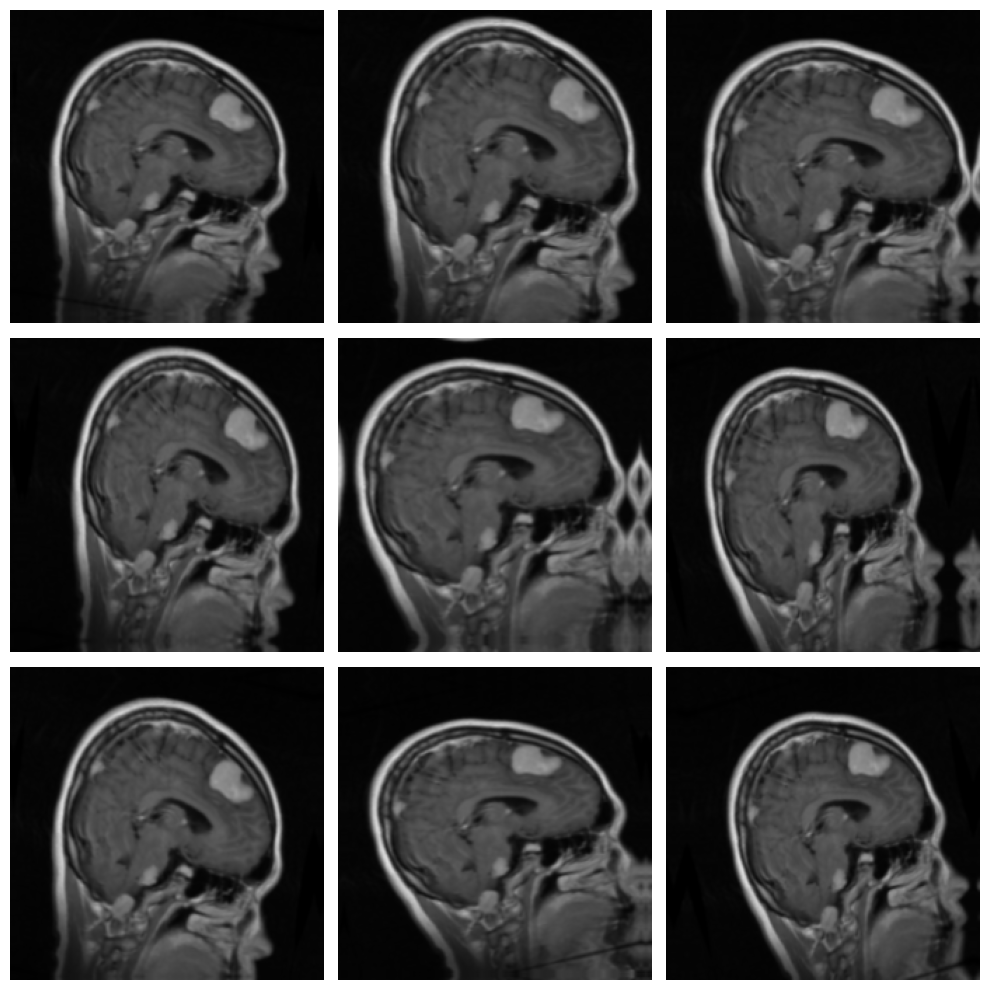

In [17]:

for images, labels in Train_ds.take(1):
      first_image = images[0]

      plt.figure(figsize=(10, 10))

      for i in range(9):
            ax = plt.subplot(3, 3, i + 1)

            # Appliquer une transformation à la même image
            augmented_image = data_augmentation(
                  tf.expand_dims(first_image, axis=0),
                  training=True
            )

            # Reconvertir les pixels de [-1, 1] vers [0, 1]
            image_to_display = (augmented_image[0] + 1.0) / 2.0
            image_to_display = tf.clip_by_value(
                  image_to_display, 0.0, 1.0
            )

            plt.imshow(image_to_display.numpy())
            plt.axis("off")

      plt.tight_layout()
      plt.savefig(
            "transfer_learning/image_apres_data_augmentation.png"
      )
plt.show()


In [18]:
IMG_SHAPE = image_size + (3,)
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE, include_top=False, weights='imagenet')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [19]:
image_batch, label_batch = next(iter(Train_ds))
feature_batch = base_model(image_batch, training=False)
print(image_batch)

I0000 00:00:1792850591.641512    2097 cuda_dnn.cc:529] Loaded cuDNN version 90300


tf.Tensor(
[[[[-0.99215686 -0.99215686 -0.99215686]
   [-0.99215686 -0.99215686 -0.99215686]
   [-0.99215686 -0.99215686 -0.99215686]
   ...
   [-0.99215686 -0.99215686 -0.99215686]
   [-0.99215686 -0.99215686 -0.99215686]
   [-0.99215686 -0.99215686 -0.99215686]]

  [[-0.99215686 -0.99215686 -0.99215686]
   [-0.99215686 -0.99215686 -0.99215686]
   [-0.99215686 -0.99215686 -0.99215686]
   ...
   [-0.99215686 -0.99215686 -0.99215686]
   [-0.99215686 -0.99215686 -0.99215686]
   [-0.99215686 -0.99215686 -0.99215686]]

  [[-0.99215686 -0.99215686 -0.99215686]
   [-0.99215686 -0.99215686 -0.99215686]
   [-0.99215686 -0.99215686 -0.99215686]
   ...
   [-0.99215686 -0.99215686 -0.99215686]
   [-0.99215686 -0.99215686 -0.99215686]
   [-0.99215686 -0.99215686 -0.99215686]]

  ...

  [[-0.99215686 -0.99215686 -0.99215686]
   [-0.99215686 -0.99215686 -0.99215686]
   [-0.99215686 -0.99215686 -0.99215686]
   ...
   [-0.99215686 -0.99215686 -0.99215686]
   [-0.99215686 -0.99215686 -0.99215686]
   [-

In [20]:
base_model.trainable = False

In [21]:
base_model.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [23]:
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average = global_average_layer(feature_batch)
print(feature_batch_average.shape)

(32, 1280)


In [25]:
prediction_layer = tf.keras.layers.Dense(4, activation="softmax")
prediction_batch = prediction_layer(feature_batch_average)
print(prediction_batch.shape)

(32, 4)


In [26]:
# preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
# x = preprocess_input(x)
x = base_model(x, training=False)
x  = global_average_layer(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)

In [27]:
base_learing_rate = 0.0001
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learing_rate),
            loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
      metrics=['accuracy'])

In [28]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [29]:
len(model.trainable_variables)

2

In [30]:
loss0, accuracy0 = model.evaluate(Val_ds)
print('initial loss {:.2f}'.format(loss0))
print('initial accuracy {:.2f}'.format(accuracy0))

/venv/main/lib/python3.10/site-packages/keras/src/backend/tensorflow/nn.py:708: UserWarning: "`sparse_categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


22/22 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - accuracy: 0.3881 - loss: 1.6453
initial loss 1.73
initial accuracy 0.37


In [31]:
# Path("models").mkdir(parents=True, exist_ok=True)
# Path("backup").mkdir(parents=True, exist_ok=True)

output_dir = Path("/transfer_learning/models")
backup_dir = Path("/transfer_learning/backup")

output_dir.mkdir(parents=True, exist_ok=True)
backup_dir.mkdir(parents=True, exist_ok=True)

In [32]:
# checkpoint = ModelCheckpoint(
#     filepath=str(output_dir / "model_epoch_{epoch:03d}.keras"),
#     monitor="val_accuracy",
#     save_best_only=False,
#     save_weights_only=False,
#     save_freq="epoch",
#     verbose=1
# )
checkpoint_best = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(output_dir / "best_model.keras"),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)
callback = EarlyStopping(monitor='val_loss',patience=4, restore_best_weights=True)
backup = BackupAndRestore(
    '/transfer_learning/backup/', save_freq="epoch", double_checkpoint=True, delete_checkpoint=False
)

In [33]:
debut = time.time()

history = model.fit(Train_ds, epochs=EPOCHS, 
                  validation_data=(Val_ds),  callbacks=[callback, backup, checkpoint_best])

fin = time.time()

duree = fin - debut

print(f"Durée de l'entraînement : {duree:.2f} secondes")
print(f"Durée en minutes : {duree / 60:.2f} minutes")

Epoch 1/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.4126 - loss: 1.3855
Epoch 1: val_loss improved from inf to 0.91802, saving model to /transfer_learning/models/best_model.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 16s 66ms/step - accuracy: 0.4130 - loss: 1.3844 - val_accuracy: 0.6273 - val_loss: 0.9180
Epoch 2/20
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.6314 - loss: 0.8833
Epoch 2: val_loss improved from 0.91802 to 0.75084, saving model to /transfer_learning/models/best_model.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 62ms/step - accuracy: 0.6316 - loss: 0.8828 - val_accuracy: 0.7255 - val_loss: 0.7508
Epoch 3/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.7197 - loss: 0.7409
Epoch 3: val_loss improved from 0.75084 to 0.66387, saving model to /transfer_learning/models/best_model.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 12s 67ms/step - accuracy: 0.7198 - loss: 0.7406 - val_accuracy: 0.7639 - val_loss: 0.6639
Epoch 4/20
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step 

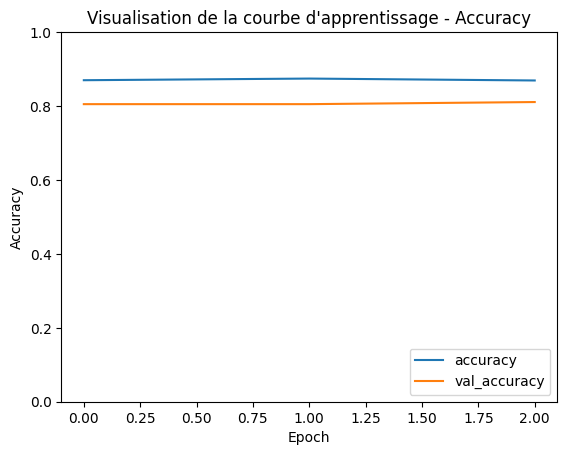

In [48]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
plt.title("Visualisation de la courbe d'apprentissage - Accuracy")
plt.savefig("/transfer_learning/accuracy_visualisation.png")

22/22 - 1s - 66ms/step - accuracy: 0.7977 - loss: 0.5648


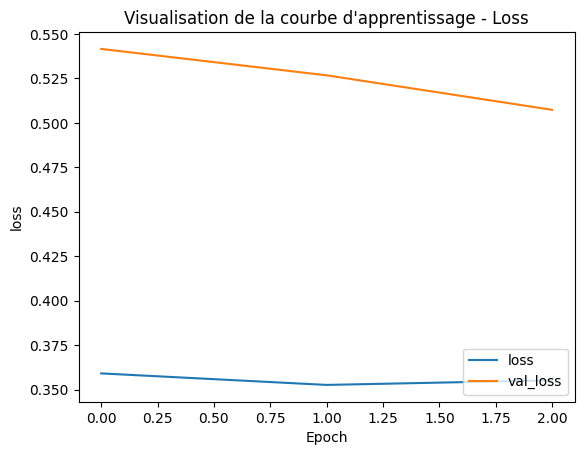

In [49]:
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label = 'val_loss')
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.title("Visualisation de la courbe d'apprentissage - Loss")
plt.legend(loc='lower right')
plt.savefig("/transfer_learning/loss_visualisation.png")
test_loss, test_acc = model.evaluate(Test_ds, verbose=2)

In [50]:
Y = model.predict(Test_ds)
y_pred=np.argmax(Y, axis=1)
y_pred

22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 95ms/step


array([3, 0, 2, 3, 3, 3, 1, 3, 3, 1, 1, 0, 3, 0, 3, 2, 1, 1, 1, 2, 3, 3,
       3, 0, 3, 3, 3, 3, 2, 3, 3, 2, 2, 0, 1, 3, 3, 1, 3, 1, 2, 2, 1, 3,
       3, 3, 2, 1, 3, 0, 2, 3, 3, 3, 2, 2, 3, 2, 3, 0, 1, 2, 3, 1, 3, 2,
       2, 0, 2, 2, 2, 3, 1, 0, 1, 3, 3, 3, 2, 2, 3, 1, 0, 3, 3, 2, 3, 3,
       2, 1, 1, 2, 0, 0, 2, 3, 2, 1, 2, 3, 3, 0, 3, 2, 0, 1, 0, 3, 2, 3,
       2, 2, 3, 0, 2, 1, 0, 1, 1, 1, 2, 3, 1, 3, 3, 1, 0, 0, 3, 2, 0, 2,
       3, 1, 0, 0, 2, 2, 2, 2, 2, 3, 3, 3, 3, 1, 1, 1, 2, 3, 3, 0, 2, 3,
       2, 2, 2, 3, 0, 0, 1, 3, 3, 3, 0, 3, 2, 0, 1, 3, 3, 1, 1, 1, 3, 3,
       1, 1, 0, 3, 2, 2, 2, 0, 3, 1, 2, 2, 2, 3, 3, 3, 1, 0, 3, 2, 3, 3,
       2, 1, 0, 3, 3, 3, 0, 2, 3, 2, 1, 3, 0, 3, 1, 3, 2, 0, 3, 2, 3, 2,
       2, 3, 0, 1, 0, 3, 3, 3, 3, 2, 3, 0, 2, 3, 0, 3, 3, 0, 1, 1, 1, 2,
       3, 1, 0, 3, 2, 3, 0, 2, 3, 2, 2, 0, 3, 2, 1, 3, 1, 2, 2, 3, 3, 1,
       2, 1, 2, 3, 3, 3, 3, 1, 2, 3, 0, 2, 1, 3, 3, 0, 2, 2, 1, 0, 0, 1,
       1, 3, 3, 1, 2, 3, 0, 3, 1, 2, 0, 2, 2, 0, 3,

In [51]:
y_true = np.concatenate([
    labels.numpy() for  images, labels in Test_ds
])

Sur les 164 images de meningioma, seulement 86 sont correctement identifiées. 57 sont classées comme pituitary, soit environ 35 % de cette classe.
Le modèle semble donc avoir tendance à privilégier la classe pituitary lorsqu'il hésite sur certaines images.

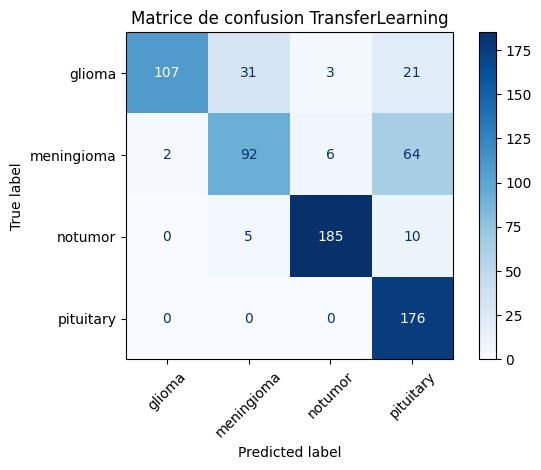

<Figure size 640x480 with 0 Axes>

In [52]:
cm = confusion_matrix(y_true, y_pred)

# effectifs = Counter(labels)
tensor_set = {labels.ref()}
tensor_set
noms_classes = list(labels_par_dossier.keys())

cms = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=noms_classes)
cms.plot(cmap='Blues', xticks_rotation=45)
plt.title("Matrice de confusion TransferLearning")
plt.tight_layout()
plt.show()
plt.savefig("/transfer_learning/matrice_confusion.png")

In [53]:
print(classification_report(y_true, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.98      0.66      0.79       162
           1       0.72      0.56      0.63       164
           2       0.95      0.93      0.94       200
           3       0.65      1.00      0.79       176

    accuracy                           0.80       702
   macro avg       0.83      0.79      0.79       702
weighted avg       0.83      0.80      0.79       702



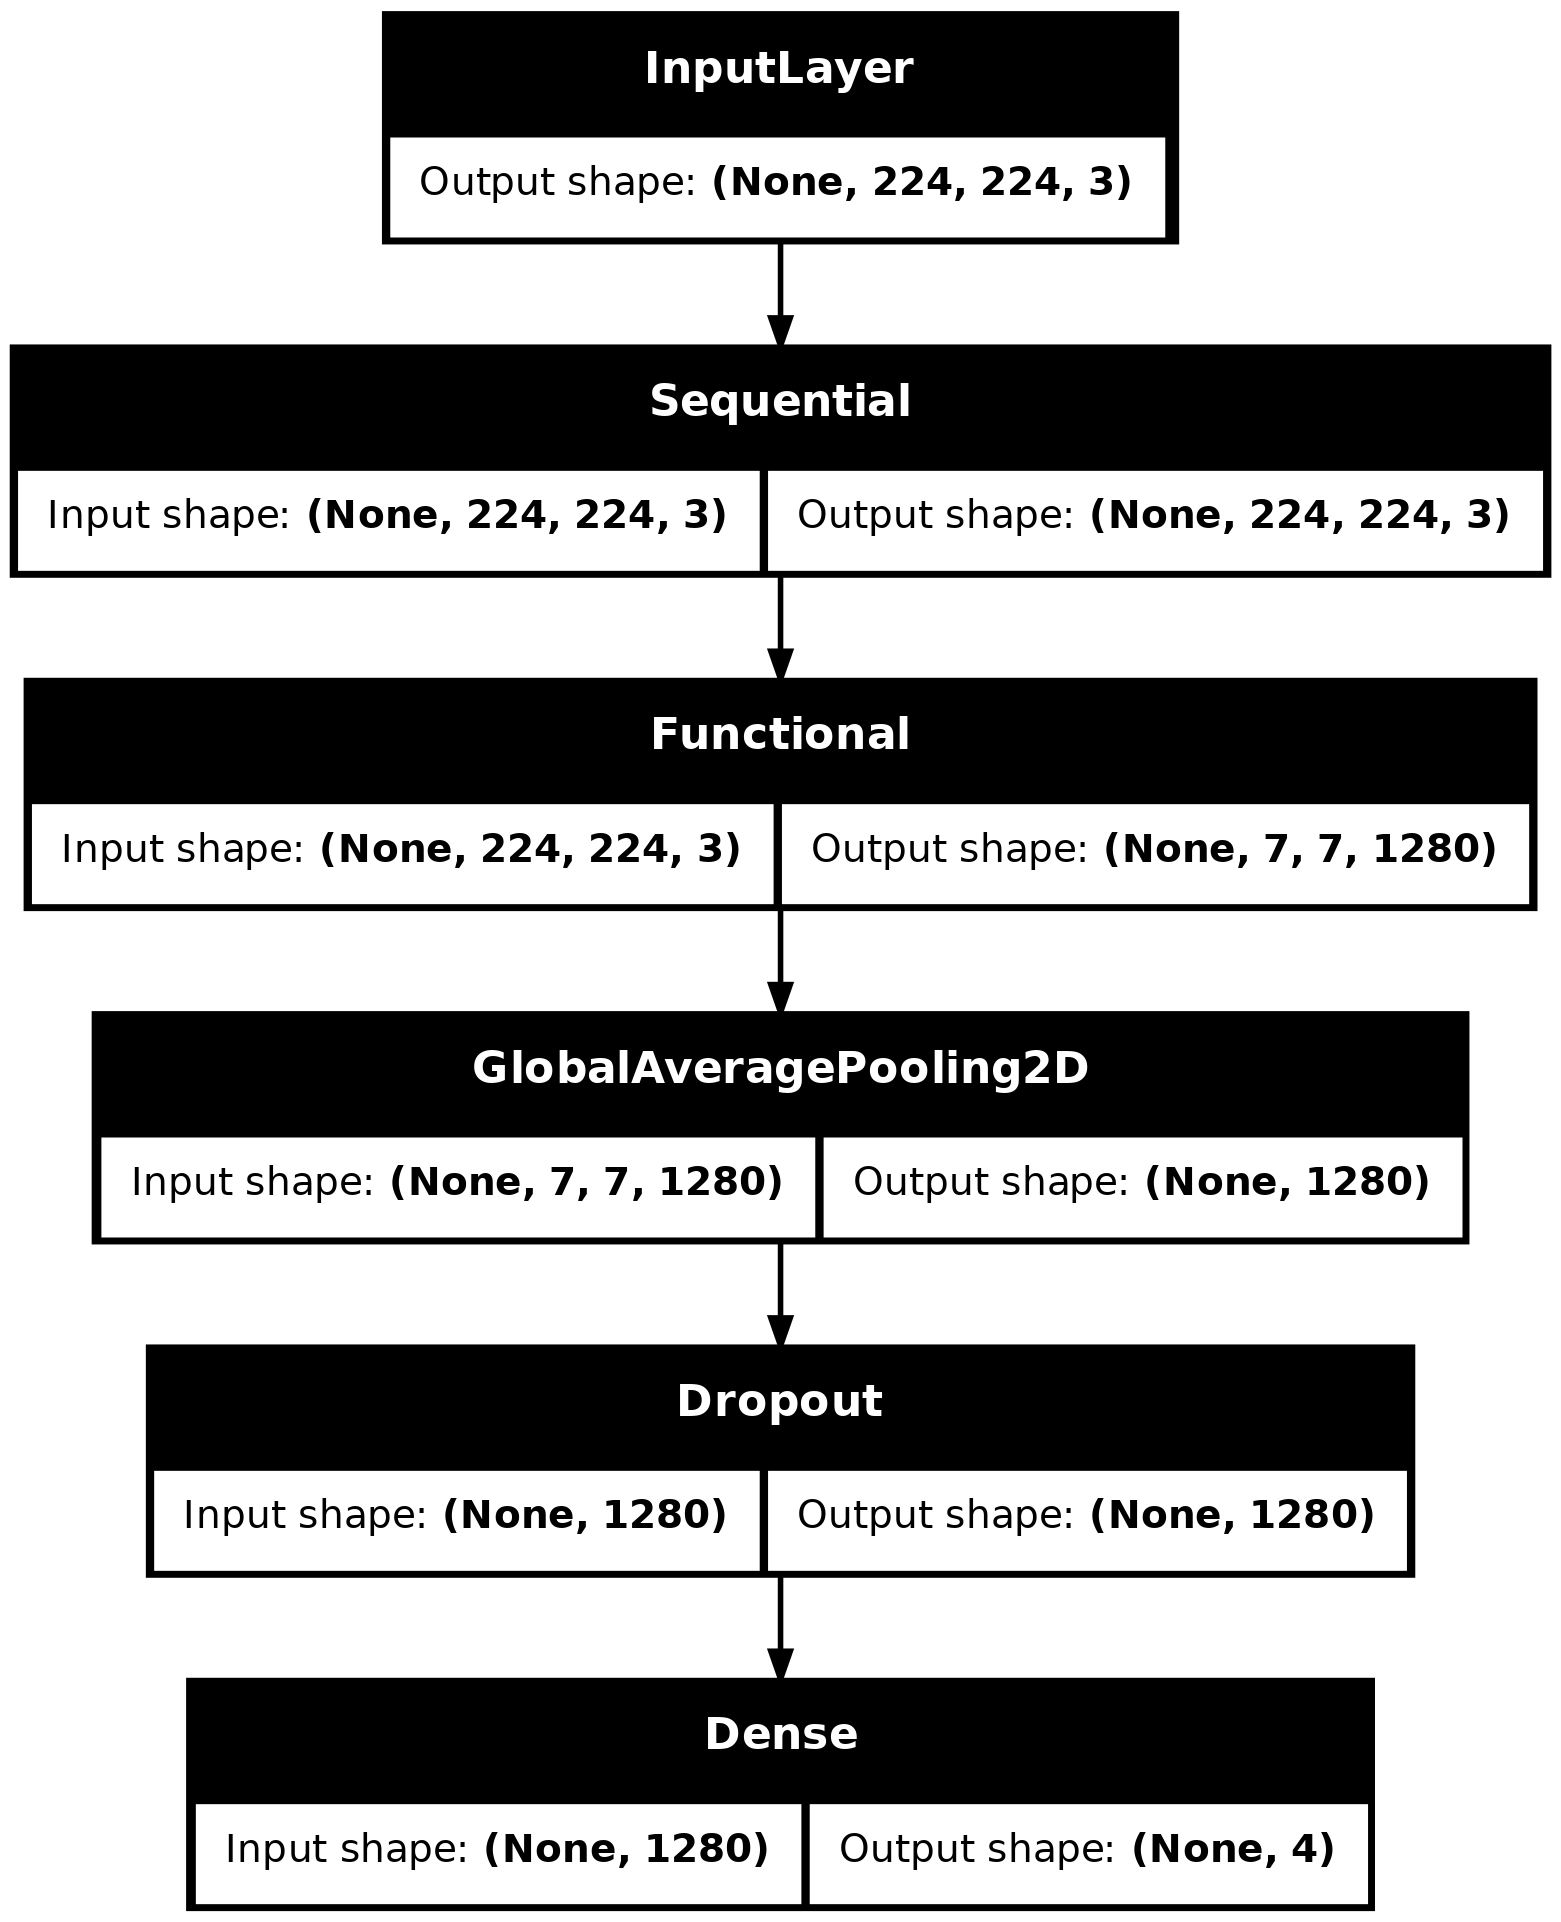

In [54]:

out_dir = Path("/transfer_learning/tmp")
out_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path1 = output_dir / "plot_model.png"
tf.keras.utils.plot_model(model, to_file=str(checkpoint_path1), show_shapes=True)

2026-10-24 15:05:05.430827: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.9607843].


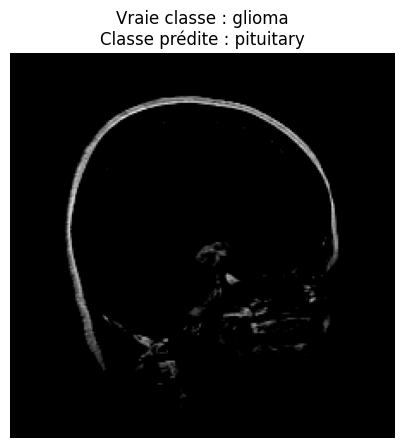

<Figure size 640x480 with 0 Axes>

In [55]:
i = 5

# Récupérer les images du dataset dans le même ordre
images_all = np.concatenate([
    images.numpy() for images, labels in Test_ds
])

class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']

# Afficher l'image exacte
plt.figure(figsize=(5, 5))
plt.imshow(images_all[i])
plt.title(
    f"Vraie classe : {class_names[int(y_true[i])]}\n"
    f"Classe prédite : {class_names[int(y_pred[i])]}"
)
plt.axis("off")
plt.show()
plt.savefig("/transfer_learning/tru_predict_image.png")


In [ ]:
best_model = load_model(output_dir / "best_model.keras")
best_model.summary()
test_loss, test_accuracy = best_model.evaluate(Test_ds)

print("Test accuracy :", test_accuracy)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,273,358 (8.67 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 10,250 (40.04 KB)

/venv/main/lib/python3.10/site-packages/keras/src/backend/tensorflow/nn.py:717: UserWarning: "`sparse_categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.7863 - loss: 0.5975
Test accuracy : 0.7863247990608215


In [ ]:
import json
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Les classes doivent respecter l'ordre utilisé pendant l'entraînement
class_names = [
    "Gliome",
    "Méningiome",
    "Aucune tumeur",
    "Tumeur hypophysaire"
]

# 1. Récupérer les vraies classes du jeu de test
y_true = np.concatenate([
    labels.numpy() for images, labels in Test_ds
])

# Gérer les labels one-hot, si nécessaire
if y_true.ndim > 1:
    y_true = np.argmax(y_true, axis=1)

# 2. Prédictions du modèle
y_prob = best_model.predict(Test_ds)
y_pred = np.argmax(y_prob, axis=1)

# 3. Métriques globales
metrics = {
    "model" : "transfer_learning",
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "precision": float(
        precision_score(y_true, y_pred, average="weighted", zero_division=0)
    ),
    "recall": float(
        recall_score(y_true, y_pred, average="weighted", zero_division=0)
    ),
    "f1_score": float(
        f1_score(y_true, y_pred, average="weighted", zero_division=0)
    ),

    # 4. Matrice de confusion
    "confusion_matrix": confusion_matrix(
        y_true, y_pred, labels=range(len(class_names))
    ).tolist(),

    "class_names": class_names,

    # 5. Rapport détaillé par classe
    "classification_report": classification_report(
        y_true,
        y_pred,
        labels=range(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
}

# 6. Courbes d'apprentissage enregistrées pendant model.fit()
if "history" in globals() and history is not None:
    metrics["learning_curves"] = {
        key: [float(value) for value in values]
        for key, values in history.history.items()
    }

# 7. Enregistrer le JSON dans le projet

Path("/transfer_learning/metrics").mkdir(parents=True, exist_ok=True)
output_path = Path("/transfer_learning/metrics/metrics_transfer.json")

with output_path.open("w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4, ensure_ascii=False)

print(f"Métriques sauvegardées dans : {output_path.resolve()}")

22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step
Métriques sauvegardées dans : /transfer_learning/metrics/metrics_transfer.json


22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 80ms/step

=== Métriques globales ===
accuracy: 0.7934
precision_macro: 0.8236
recall_macro: 0.8236
f1_weighted: 0.7900

=== Rapport par classe ===
              precision    recall  f1-score   support

      glioma       0.97      0.65      0.78       162
  meningioma       0.73      0.55      0.62       164
     notumor       0.96      0.93      0.94       200
   pituitary       0.64      1.00      0.78       176

    accuracy                           0.79       702
   macro avg       0.82      0.78      0.78       702
weighted avg       0.83      0.79      0.79       702



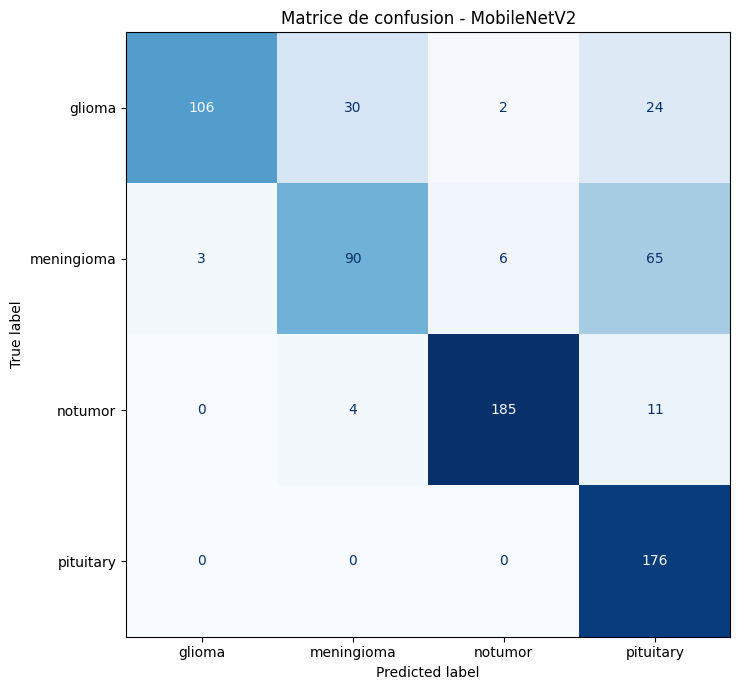


Resultats sauvgardés dasn : /fine_tuning/artifacts/metrics


In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt

def plot_training_history(history, output_dir):
      output_dir = Path(output_dir)
      output_dir.mkdir(parents=True, exist_ok=True)

      history_data = history.history

      #Courbe d'accuracy

      plt.figure(figsize=(8,5))
      plt.plot(history_data['accuracy'], label ='Train accuracy')

      if 'val_accuracy' in history_data:
            plt.plot(history_data['val_accuracy'], label ='Validation accuracy')

      plt.title('Accuracy - Fine Tuning MobileNetV2')
      plt.xlabel('Epoque')
      plt.ylabel('Accuracy')
      plt.legend()
      plt.grid(True)
      plt.tight_layout()
      plt.savefig(output_dir / "accuracy.png", dpi=150)
      plt.show()
      plt.close()


      #Courbe de loss
      plt.figure(figsize=(8,5))
      plt.plot(history_data['loss'], label ='Train loss')
      
      if 'val_loss' in history_data:
            plt.plot(history_data['val_loss'], label ='Validation loss')

      plt.title('Loss - Fine Tuning MobileNetV2')
      plt.xlabel('Epoque')
      plt.ylabel('Loss')
      plt.legend()
      plt.grid(True)
      plt.tight_layout()
      plt.savefig(output_dir / "loss.png", dpi=150)
      plt.show()
      plt.close()

######
from pathlib import Path
import json

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)


def evaluate_model(model, test_ds, class_names, output_dir):
      output_dir = Path(output_dir)
      output_dir.mkdir(parents=True, exist_ok=True)

      #1 Recuperer les vrais labels
      y_true = np.concatenate([
            labels.numpy() for _, labels in test_ds
      ])

      # 2 Recuperer les probabilites

      y_prob = model.predict(test_ds, verbose=1)

      # 3 Transformer les probalibites en classes predites

      y_pred = np.argmax(y_prob, axis=1)

      # Verifier la correspondance entre les classes et les indices

      class_labels = list(range(len(class_names)))

      # 4 Calculer les metriques globals

      metrics = {
            "accuracy" : float(accuracy_score(y_true=y_true, y_pred=y_pred)),
            "precision_macro" : float(
                  precision_score(
                        y_true=y_true,
                        y_pred=y_pred,labels=class_labels, average='macro', zero_division=0)),

            "recall_macro" : float(
            precision_score(
                  y_true=y_true,
                  y_pred=y_pred,
                  labels=class_labels,
                  average='macro',
                  zero_division=0)),
            "f1_weighted" : float(
            f1_score(
                  y_true=y_true,
                  y_pred=y_pred,
                  labels=class_labels,
                  average='weighted',
                  zero_division=0)),
      }

      # 5 Rapport detailler par class

      raport = classification_report(
            y_true=y_true,
            y_pred=y_pred,
            labels=class_labels,
            target_names=class_names,
            output_dict=True,
            zero_division=0
      )

      print("\n=== Métriques globales ===")
      for name, value in metrics.items():
            print(f"{name}: {value:.4f}")

      print("\n=== Rapport par classe ===")
      print(
            classification_report(
                  y_true,
                  y_pred,
                  labels=class_labels,
                  target_names=class_names,
                  zero_division=0
            )
      )

      # 6 Metrice de confusion
      cm= confusion_matrix(
            y_true=y_true,
            y_pred=y_pred,
            labels=class_labels
      )

      display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

      fig, ax = plt.subplots(figsize=(8,7))
      display.plot(
            ax=ax,
            cmap='Blues',
            values_format='d',
            colorbar=False
      )

      ax.set_title("Matrice de confusion - MobileNetV2")
      fig.tight_layout()
      fig.savefig(
            output_dir / "confusion_matrix.png", dpi=150,
            bbox_inches='tight'
      )
      plt.show()
      plt.close(fig)

      # 7 Sauvegarder les résultats en JSON
      results = {
            "metrics": metrics,
            "classification_report": raport,
            "confusion_matrix": cm.tolist(),
            "class_names": class_names,
            "test_samples": int(len(y_true))
      }

      with open(output_dir / "metrics.json", "w", encoding='utf-8') as f:
            json.dump(results, f, indent=4, ensure_ascii=False)

      print(f"\nResultats sauvgardés dasn : {output_dir}")

      return results

model = tf.keras.models.load_model(
    "/fine_tuni/models/best_model.keras"
) 
labels_par_dossier = {
    "glioma": 0,
    "meningioma": 1,
    "notumor": 2,
    "pituitary": 3
}

class_names = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

# from src.evaluation.plots import plot_training_history
# from src.evaluation.metrics import evaluate_model

# Visualisation de l'entraînement
# plot_training_history(
#     history,
#     output_dir="/transfer_learning/artifacts/plots"
# )

# Évaluation finale sur le jeu de test
results = evaluate_model(
    model=model,
    test_ds=Test_ds,
    class_names=class_names,
    output_dir="/fine_tuning/artifacts/metrics"
)


In [16]:
from pathlib import Path
import mlflow


In [35]:

def log_transfer_learning_experiment(model_path, results, training_duration, epochs, batch_size, learning_rate, artifact_dict=None):
      mlflow.set_tracking_uri('http://127.0.0.1:5000')
      mlflow.set_experiment('NeuroVision_AI')

      with mlflow.start_run(run_name='MobileNetV2_FineTuning') as run:

            #Parameteres de l'experience
            mlflow.log_params({
                  "model" : "MobileNetV2",
                  "strategy" : "fine_tuning",
                  "image_size" : "224x224",
                  "num_classes" : 4,
                  "epochs_requested" : epochs,
                  "Batch_size" : batch_size,
                  "learning_rate" : learning_rate,
                  "optimizer" : "Adam",
                  "loss" : "SparseCategoricalCrossentropy",
                  "augmentation" : True
            })

            #Metriques globales calculées sur le jeu de test

            for name, value in results['metrics'].items():
                  mlflow.log_metric(name, float(value))

            mlflow.log_metric("training_duration_seconds", float(training_duration))

            # Rapport , matrice de confusion et autres fichiers : 
            if artifact_dict:
                  for directory in artifact_dict:
                        directory = Path(directory)
                        if directory.exists():
                              mlflow.log_artifacts(str(directory))

            # Enregistrer le model existant sans réentrainer

            if Path(model_path).exists():
                  mlflow.log_artifact(str(model_path), artifact_path="model_files")
            else:
                  raise FileNotFoundError(
                        f"Mode introuvable : {model_path}"
                  )
            print("Run Mlflow enregistré : ", run.info.run_id)

log_transfer_learning_experiment(
      model_path="/fine_tuning/models/best_model.keras",
      results=results,
      training_duration=training_duration,
      epochs=EPOCHS,
      batch_size=BATCH_SIZE,
      learning_rate=1e-5,
      artifact_dict=[
            "/fine_tuning/artifacts/plots",
            "/fine_tuning/artifacts/metrics"
      ]
)

Run Mlflow enregistré :  eb77e0fd54e34d0c8e265b4613bddc7d
🏃 View run MobileNetV2_FineTuning at: http://127.0.0.1:5000/#/experiments/1/runs/eb77e0fd54e34d0c8e265b4613bddc7d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [36]:
import mlflow

print("MLflow version :", mlflow.__version__)
print("Tracking URI :", mlflow.get_tracking_uri())

experiments = mlflow.search_experiments()

for experiment in experiments:
    print(experiment.experiment_id, experiment.name)

MLflow version : 3.17.2
Tracking URI : http://127.0.0.1:5000
1 NeuroVision_AI
0 Default


In [37]:
experiment = mlflow.get_experiment_by_name("NeuroVision_AI")

if experiment is not None:
    runs = mlflow.search_runs(
        experiment_ids=[experiment.experiment_id]
    )

    print(runs[[
        col for col in runs.columns
        if col in [
            "run_id",
            "status",
            "params.model",
            "params.strategy",
            "metrics.accuracy",
            "metrics.f1_macro"
        ]
    ]])
else:
    print("Expérience NeuroVision_AI introuvable.")

                             run_id    status  metrics.accuracy params.model  \
0  eb77e0fd54e34d0c8e265b4613bddc7d  FINISHED          0.793447  MobileNetV2   
1  dae79ad7b245410ea5562887075c44b1  FINISHED          0.797721  MobileNetV2   
2  e9a2cc99d78d4785a4e49dc387ee7106  FINISHED          0.797721  MobileNetV2   
3  b3948bf648224401925d4a3bf8adc2d9    FAILED          0.797721  MobileNetV2   
4  85e66a437f6c4f3399cfa2b1b844a4f6    FAILED          0.797721  MobileNetV2   

     params.strategy  
0        fine_tuning  
1  transfer_learning  
2  transfer_learning  
3  transfer_learning  
4  transfer_learning  


In [39]:
def  build_cnn():

      """Construit le CNN de base comme dans le notebook."""
      data_augmentation= build_data_augmentation()
      # API Sequentiel
      model = models.Sequential()
      model.add(layers.Input(shape=(224, 224, 3)))
      model.add(data_augmentation)
      model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)))
      model.add(layers.MaxPooling2D((2, 2)))
      model.add(layers.Conv2D(64, (3, 3), activation='relu'))
      model.add(layers.MaxPooling2D((2, 2)))
      model.add(layers.Conv2D(64, (3, 3), activation='relu'))
      model.add(layers.Flatten())
      model.add(layers.Dense(64, activation='relu'))
      model.add(layers.Dense(4))

      return model

OUTPUT_DIR = "/cnn/models"
BACKUP_DIR = "/cnn/backup"

# 1. Construire le modèle
model = build_cnn()

# 2. Compiler
model = compile_mode(model, learning_rate=0.0001)

# 3. Vérifier l'architecture
model.summary()

# 4. Évaluer avant entraînement
# initial_metrics = evaluate_initial_model(model, Val_ds)

# 5. Créer les callbacks
callbacks = create_callbacks(OUTPUT_DIR, BACKUP_DIR)

# 6. Entraîner
history, training_duration = train_model(
      model,
      Train_ds,
      Val_ds,
      epochs=EPOCHS,
      callbacks=callbacks
)



/venv/main/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 173056)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │    11,075,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,132,228 (42.47 MB)

 Trainable params: 11,132,228 (42.47 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.2392 - loss: 1.4943
Epoch 1: val_loss improved from None to 1.36897, saving model to /cnn/models/best_model.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 18s 84ms/step - accuracy: 0.2467 - loss: 1.3801 - val_accuracy: 0.2489 - val_loss: 1.3690
Epoch 2/20
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.2754 - loss: 1.3625
Epoch 2: val_loss improved from 1.36897 to 1.31834, saving model to /cnn/models/best_model.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - accuracy: 0.2885 - loss: 1.3556 - val_accuracy: 0.3243 - val_loss: 1.3183
Epoch 3/20
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.3153 - loss: 1.3416
Epoch 3: val_loss improved from 1.31834 to 1.30474, saving model to /cnn/models/best_model.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 76ms/step - accuracy: 0.3224 - loss: 1.3545 - val_accuracy: 0.3300 - val_loss: 1.3047
Epoch 4/20
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.3025 - loss: 1.3737
Epoch 4

22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step

=== Métriques globales ===
accuracy: 0.3276
precision_macro: 0.2884
recall_macro: 0.2884
f1_weighted: 0.2353

=== Rapport par classe ===
              precision    recall  f1-score   support

      glioma       0.26      1.00      0.41       162
  meningioma       0.00      0.00      0.00       164
     notumor       0.89      0.34      0.49       200
   pituitary       0.00      0.00      0.00       176

    accuracy                           0.33       702
   macro avg       0.29      0.34      0.23       702
weighted avg       0.31      0.33      0.24       702



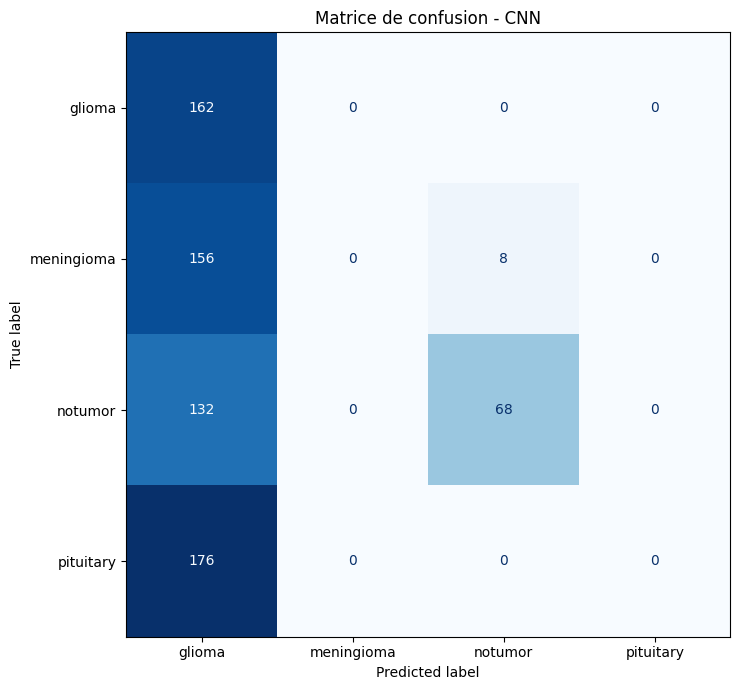


Resultats sauvgardés dasn : /cnn/artifacts/metrics


In [40]:
from pathlib import Path
import matplotlib.pyplot as plt

def plot_training_history(history, output_dir):
      output_dir = Path(output_dir)
      output_dir.mkdir(parents=True, exist_ok=True)

      history_data = history.history

      #Courbe d'accuracy

      plt.figure(figsize=(8,5))
      plt.plot(history_data['accuracy'], label ='Train accuracy')

      if 'val_accuracy' in history_data:
            plt.plot(history_data['val_accuracy'], label ='Validation accuracy')

      plt.title('Accuracy - Fine Tuning MobileNetV2')
      plt.xlabel('Epoque')
      plt.ylabel('Accuracy')
      plt.legend()
      plt.grid(True)
      plt.tight_layout()
      plt.savefig(output_dir / "accuracy.png", dpi=150)
      plt.show()
      plt.close()


      #Courbe de loss
      plt.figure(figsize=(8,5))
      plt.plot(history_data['loss'], label ='Train loss')
      
      if 'val_loss' in history_data:
            plt.plot(history_data['val_loss'], label ='Validation loss')

      plt.title('Loss - Fine Tuning MobileNetV2')
      plt.xlabel('Epoque')
      plt.ylabel('Loss')
      plt.legend()
      plt.grid(True)
      plt.tight_layout()
      plt.savefig(output_dir / "loss.png", dpi=150)
      plt.show()
      plt.close()

######
from pathlib import Path
import json

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)


def evaluate_model(model, test_ds, class_names, output_dir):
      output_dir = Path(output_dir)
      output_dir.mkdir(parents=True, exist_ok=True)

      #1 Recuperer les vrais labels
      y_true = np.concatenate([
            labels.numpy() for _, labels in test_ds
      ])

      # 2 Recuperer les probabilites

      y_prob = model.predict(test_ds, verbose=1)

      # 3 Transformer les probalibites en classes predites

      y_pred = np.argmax(y_prob, axis=1)

      # Verifier la correspondance entre les classes et les indices

      class_labels = list(range(len(class_names)))

      # 4 Calculer les metriques globals

      metrics = {
            "accuracy" : float(accuracy_score(y_true=y_true, y_pred=y_pred)),
            "precision_macro" : float(
                  precision_score(
                        y_true=y_true,
                        y_pred=y_pred,labels=class_labels, average='macro', zero_division=0)),

            "recall_macro" : float(
            precision_score(
                  y_true=y_true,
                  y_pred=y_pred,
                  labels=class_labels,
                  average='macro',
                  zero_division=0)),
            "f1_weighted" : float(
            f1_score(
                  y_true=y_true,
                  y_pred=y_pred,
                  labels=class_labels,
                  average='weighted',
                  zero_division=0)),
      }

      # 5 Rapport detailler par class

      raport = classification_report(
            y_true=y_true,
            y_pred=y_pred,
            labels=class_labels,
            target_names=class_names,
            output_dict=True,
            zero_division=0
      )

      print("\n=== Métriques globales ===")
      for name, value in metrics.items():
            print(f"{name}: {value:.4f}")

      print("\n=== Rapport par classe ===")
      print(
            classification_report(
                  y_true,
                  y_pred,
                  labels=class_labels,
                  target_names=class_names,
                  zero_division=0
            )
      )

      # 6 Metrice de confusion
      cm= confusion_matrix(
            y_true=y_true,
            y_pred=y_pred,
            labels=class_labels
      )

      display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

      fig, ax = plt.subplots(figsize=(8,7))
      display.plot(
            ax=ax,
            cmap='Blues',
            values_format='d',
            colorbar=False
      )

      ax.set_title("Matrice de confusion - CNN")
      fig.tight_layout()
      fig.savefig(
            output_dir / "confusion_matrix.png", dpi=150,
            bbox_inches='tight'
      )
      plt.show()
      plt.close(fig)

      # 7 Sauvegarder les résultats en JSON
      results = {
            "metrics": metrics,
            "classification_report": raport,
            "confusion_matrix": cm.tolist(),
            "class_names": class_names,
            "test_samples": int(len(y_true))
      }

      with open(output_dir / "metrics.json", "w", encoding='utf-8') as f:
            json.dump(results, f, indent=4, ensure_ascii=False)

      print(f"\nResultats sauvgardés dasn : {output_dir}")

      return results

model = tf.keras.models.load_model(
    "/cnn/models/best_model.keras"
) 
labels_par_dossier = {
    "glioma": 0,
    "meningioma": 1,
    "notumor": 2,
    "pituitary": 3
}

class_names = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

# from src.evaluation.plots import plot_training_history
# from src.evaluation.metrics import evaluate_model

# Visualisation de l'entraînement
# plot_training_history(
#     history,
#     output_dir="/transfer_learning/artifacts/plots"
# )

# Évaluation finale sur le jeu de test
results = evaluate_model(
    model=model,
    test_ds=Test_ds,
    class_names=class_names,
    output_dir="/cnn/artifacts/metrics"
)


In [41]:
from pathlib import Path
import mlflow

def log_transfer_learning_experiment(model_path, results, training_duration, epochs, batch_size, learning_rate, artifact_dict=None):
      mlflow.set_tracking_uri('http://127.0.0.1:5000')
      mlflow.set_experiment('NeuroVision_AI')

      with mlflow.start_run(run_name='cnn') as run:

            #Parameteres de l'experience
            mlflow.log_params({
                  "model" : "cnn",
                  "strategy" : "cnn",
                  "image_size" : "224x224",
                  "num_classes" : 4,
                  "epochs_requested" : epochs,
                  "Batch_size" : batch_size,
                  "learning_rate" : learning_rate,
                  "optimizer" : "Adam",
                  "loss" : "SparseCategoricalCrossentropy",
                  "augmentation" : True
            })

            #Metriques globales calculées sur le jeu de test

            for name, value in results['metrics'].items():
                  mlflow.log_metric(name, float(value))

            mlflow.log_metric("training_duration_seconds", float(training_duration))

            # Rapport , matrice de confusion et autres fichiers : 
            if artifact_dict:
                  for directory in artifact_dict:
                        directory = Path(directory)
                        if directory.exists():
                              mlflow.log_artifacts(str(directory))

            # Enregistrer le model existant sans réentrainer

            if Path(model_path).exists():
                  mlflow.log_artifact(str(model_path), artifact_path="model_files")
            else:
                  raise FileNotFoundError(
                        f"Mode introuvable : {model_path}"
                  )
            print("Run Mlflow enregistré : ", run.info.run_id)

log_transfer_learning_experiment(
      model_path="/cnn/models/best_model.keras",
      results=results,
      training_duration=training_duration,
      epochs=EPOCHS,
      batch_size=BATCH_SIZE,
      learning_rate=1e-5,
      artifact_dict=[
            "/cnn/artifacts/plots",
            "/cnn/artifacts/metrics"
      ]
)

Run Mlflow enregistré :  49f61d0e50f74f018c1a226849b0a8ae
🏃 View run cnn at: http://127.0.0.1:5000/#/experiments/1/runs/49f61d0e50f74f018c1a226849b0a8ae
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
